# LAB | In God we trust, everyone else bring the data

**Scenario:** you are a marketing analyst. The CMO wants to split a **$500K monthly budget across the marketing channels** and asks you for a **statistically rigorous** recommendation. A false positive means moving money to a channel that isn't really better.

**How to use this notebook:**
- Cells marked **`# TODO`** are yours to complete. Replace every `...` with your code.
- 💡 **Hints** point to the statistics notebook (`03_statistical_analysis.ipynb`), where you saw each idea.
- Run the cells **in order**, top to bottom.

| Part | You will… | Concept from class |
|---|---|---|
| 1 | Find, load and clean a real dataset; compute metrics | A score is an **estimate** |
| 2 | Compare channels (t-test, Fisher) + effect size | p-value, **pick the test by the data**, Cohen's d |
| 3 | Correct for many comparisons | Bonferroni vs Benjamini-Hochberg |
| 4 | Check whether you have enough data | Power and sample size |
| 5 | Turn statistics into a recommendation | Confidence intervals, real vs worth it |

## Part 1 — Dataset discovery & exploration (45–60 min)
### Step 1: Find a dataset (max 30 min)

Search [Kaggle](https://www.kaggle.com/datasets) or [Hugging Face](https://huggingface.co/datasets) for: *marketing channels, advertising campaigns, campaign performance, ad spend, e-commerce conversion, A/B testing*.

Your dataset should have:
- **3+ groups** to compare (channels, campaigns, ad groups…)
- **performance columns**: impressions, clicks, conversions, cost, revenue (not always all of them)
- **repeated rows per group**, ideally one row per **day** or **week** per group (you need this for t-tests and power)

💡 **Hint:** a dataset with **one row per customer** (e.g. "responded yes/no") only works well for Fisher's test (Step 5). Prefer data with many rows per channel.

**✍️ Document your choice here:**
- **Dataset name:** Marketing Campaign Performance Dataset (22,029-row version, file `marketing_campaign.csv`)
- **Source + URL:** GitHub copy of the Kaggle dataset — https://github.com/AnithaInsights/marketing-campaign-performance-analysis (original on Kaggle: https://www.kaggle.com/datasets/manishabhatt22/marketing-campaign-performance-dataset, which has the same columns and 200,000 rows)
- **Why I chose it:** it has **6 channels** (Email, Facebook, Google Ads, Instagram, Website, YouTube), a **date for every row covering all of 2023**, and the performance columns we need (impressions, clicks, conversion rate, cost, ROI). After grouping by day we get ~365 rows per channel, which is exactly what the t-tests and the power analysis need.
- **What is one row?** In the raw file, one row = **one campaign** (company, channel, date, clicks, impressions, cost, conversion rate, ROI). After cleaning, one row = **one channel on one day** (sum of all campaigns that ran on that channel that day, ~10 per day).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from pathlib import Path
from IPython.display import Markdown, display

from scipy import stats
from scipy.stats import fisher_exact, false_discovery_control   # false_discovery_control needs SciPy 1.11+

rng = np.random.default_rng(42)          # our "dice": fixed seed so results are repeatable
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)   # all charts / CSV / memo are saved here
sns.set_theme(style="whitegrid")
ALPHA = 0.05

### Step 2: Load, explore, clean

Rename your columns to these **standard names**, so the rest of the notebook works: `date, channel, impressions, clicks, conversions, cost, revenue`. If your dataset lacks a column, leave it out and skip the metrics that need it.

In [2]:
# Load the dataset
CSV_PATH = "marketing_campaign.csv"
COLUMN_MAP = {
    "Date": "date",
    "Channel_Used": "channel",
    "Impressions": "impressions",
    "Clicks": "clicks",
    "Acquisition_Cost": "cost",
}

raw = pd.read_csv(CSV_PATH).rename(columns=COLUMN_MAP)

# Shape, column types and first rows
print("Shape:", raw.shape)
print(raw.dtypes)
raw.head()

Shape: (22029, 16)
Campaign_ID           int64
Company                 str
Campaign_Type           str
Target_Audience         str
Duration                str
channel                 str
Conversion_Rate     float64
cost                  int64
ROI                 float64
Location                str
Language                str
clicks                int64
impressions           int64
Engagement_Score      int64
Customer_Segment        str
date                    str
dtype: object


,Campaign_ID,Company,Campaign_Type,Target_Audience,Duration,channel,Conversion_Rate,cost,ROI,Location,Language,clicks,impressions,Engagement_Score,Customer_Segment,date
0,1,TechCorp,Email,Women 25-34,30 days,Facebook,5.294194,9344,62.94,Houston,English,3045,67836,5,Tech Enthusiasts,01-01-2023
1,2,Innovate Industries,Influencer,Women 35-44,45 days,Google Ads,3.326375,8783,10.67,"Washington, D.C.",German,1944,66361,4,Foodies,01-01-2023
2,3,NexGen Systems,Social Media,Women 25-34,45 days,Instagram,4.056375,9111,73.20,Miami,Spanish,3156,86240,8,Fashionistas,01-01-2023
3,4,Innovate Industries,Email,Women 25-34,45 days,Instagram,4.496375,7420,60.92,Seattle,Spanish,2388,58251,6,Foodies,01-01-2023
4,5,Data Tech Solutions,Influencer,Men 25-34,30 days,Google Ads,4.405930,2146,138.82,Chicago,English,1025,34407,5,Tech Enthusiasts,01-01-2023


In [3]:
# Clean the data
df = raw.copy()
num_cols = ["impressions", "clicks", "conversions", "cost", "revenue"]

# 1. Convert the date column and the numeric columns
df["date"] = pd.to_datetime(df["date"], format="%d-%m-%Y")
for col in ["impressions", "clicks", "cost", "Conversion_Rate", "ROI"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# The dataset has no conversions or revenue columns, so we build them:
# conversions = clicks x conversion rate (the rate is given in %)
# revenue     = cost x (1 + ROI / 100)  (ROI is given in %, e.g. -98 to +3110)
df["conversions"] = (df["clicks"] * df["Conversion_Rate"] / 100).round()
df["revenue"] = df["cost"] * (1 + df["ROI"] / 100)

# 2. Check missing values and remove impossible rows
print("Missing values per column:")
print(df.isna().sum())
rows_before = len(df)
df = df.dropna(subset=num_cols)
df = df[(df[num_cols] >= 0).all(axis=1)]
df = df[df["clicks"] <= df["impressions"]]
df = df[df["conversions"] <= df["clicks"]]
print("Impossible rows removed:", rows_before - len(df))

# One row per campaign -> one row per DAY per channel (sum of all campaigns that day)
df = df.groupby(["date", "channel"], as_index=False)[num_cols].sum()

# 3. Number of groups, rows per group, date range
print("Number of channels:", df["channel"].nunique())
print(df["channel"].value_counts())
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())

# 4. Save the cleaned data
df.to_csv(OUT / "marketing_data.csv", index=False)

Missing values per column:
Campaign_ID         0
Company             0
Campaign_Type       0
Target_Audience     0
Duration            0
channel             0
Conversion_Rate     0
cost                0
ROI                 0
Location            0
Language            0
clicks              0
impressions         0
Engagement_Score    0
Customer_Segment    0
date                0
conversions         0
revenue             0
dtype: int64
Impossible rows removed: 0
Number of channels: 6
channel
Email         365
Facebook      365
Google Ads    365
Website       365
Instagram     364
YouTube       363
Name: count, dtype: int64
Date range: 2023-01-01 to 2023-12-31


**✍️ Transformations I made:**
- Renamed columns to the standard names (`Date → date`, `Channel_Used → channel`, `Impressions → impressions`, `Clicks → clicks`, `Acquisition_Cost → cost`).
- Converted `date` with `pd.to_datetime` (format day-month-year) and the numeric columns with `pd.to_numeric(errors="coerce")`.
- The dataset has **no conversions or revenue columns**, so I derived them: `conversions = clicks × Conversion_Rate / 100` (rounded) and `revenue = cost × (1 + ROI / 100)` (ROI is in %, from −98% to +3,110%).
- Checked missing values (none) and removed impossible rows (negative values, clicks > impressions, conversions > clicks): **0 rows removed**.
- Aggregated from one row per campaign to **one row per channel per day** (sum).
- Saved the result to `outputs/marketing_data.csv`.

💡 **Think:** how many rows does each channel have? That number is your **N** for the t-tests later.
→ **363–365 days per channel** (Instagram and YouTube have 1–2 days with no campaign). So N ≈ 365 per channel for the t-tests.

### Step 3: Key marketing metrics (15–20 min)

| Metric | Formula |
|---|---|
| CTR | clicks / impressions |
| Conversion rate | conversions / clicks |
| CPA | cost / conversions (lower is better) |
| ROAS | revenue / cost (higher is better) |
| Profit · margin | revenue − cost · profit / revenue |

In [4]:
# Totals per channel, then the metrics
agg = df.groupby("channel")[num_cols].sum()
agg["CTR"] = agg["clicks"] / agg["impressions"]
agg["conv_rate"] = agg["conversions"] / agg["clicks"]
agg["CPA"] = (agg["cost"] / agg["conversions"]).where(agg["cost"] > 0)
agg["ROAS"] = (agg["revenue"] / agg["cost"]).where(agg["cost"] > 0)
agg["profit"] = agg["revenue"] - agg["cost"]
agg["profit_margin"] = agg["profit"] / agg["revenue"]
agg = agg.replace([np.inf, -np.inf], np.nan)
agg.round(3)

,impressions,clicks,conversions,cost,revenue,CTR,conv_rate,CPA,ROAS,profit,profit_margin
channel,,,,,,,,,,,
Email,185244414,8079437,397111.0,19926056,4.039718e+07,0.044,0.049,50.178,2.027,2.047112e+07,0.507
Facebook,191066585,8469381,420551.0,20640730,4.234690e+07,0.044,0.050,49.080,2.052,2.170617e+07,0.513
Google Ads,187208799,8220161,403713.0,20454601,4.110080e+07,0.044,0.049,50.666,2.009,2.064620e+07,0.502
Instagram,182953348,8018677,393744.0,20380894,4.009339e+07,0.044,0.049,51.762,1.967,1.971250e+07,0.492
Website,185538976,8167752,405089.0,20287107,4.083875e+07,0.044,0.050,50.081,2.013,2.055164e+07,0.503
YouTube,182884441,8032849,395582.0,19971070,4.016424e+07,0.044,0.049,50.485,2.011,2.019317e+07,0.503


💡 **Hint: watch out for zero-cost channels** (e.g. SEO, organic). ROAS becomes infinite, and CPA becomes **$0**, which would make the channel look like the best one. Use `.where(agg.cost > 0)` to give them no CPA.

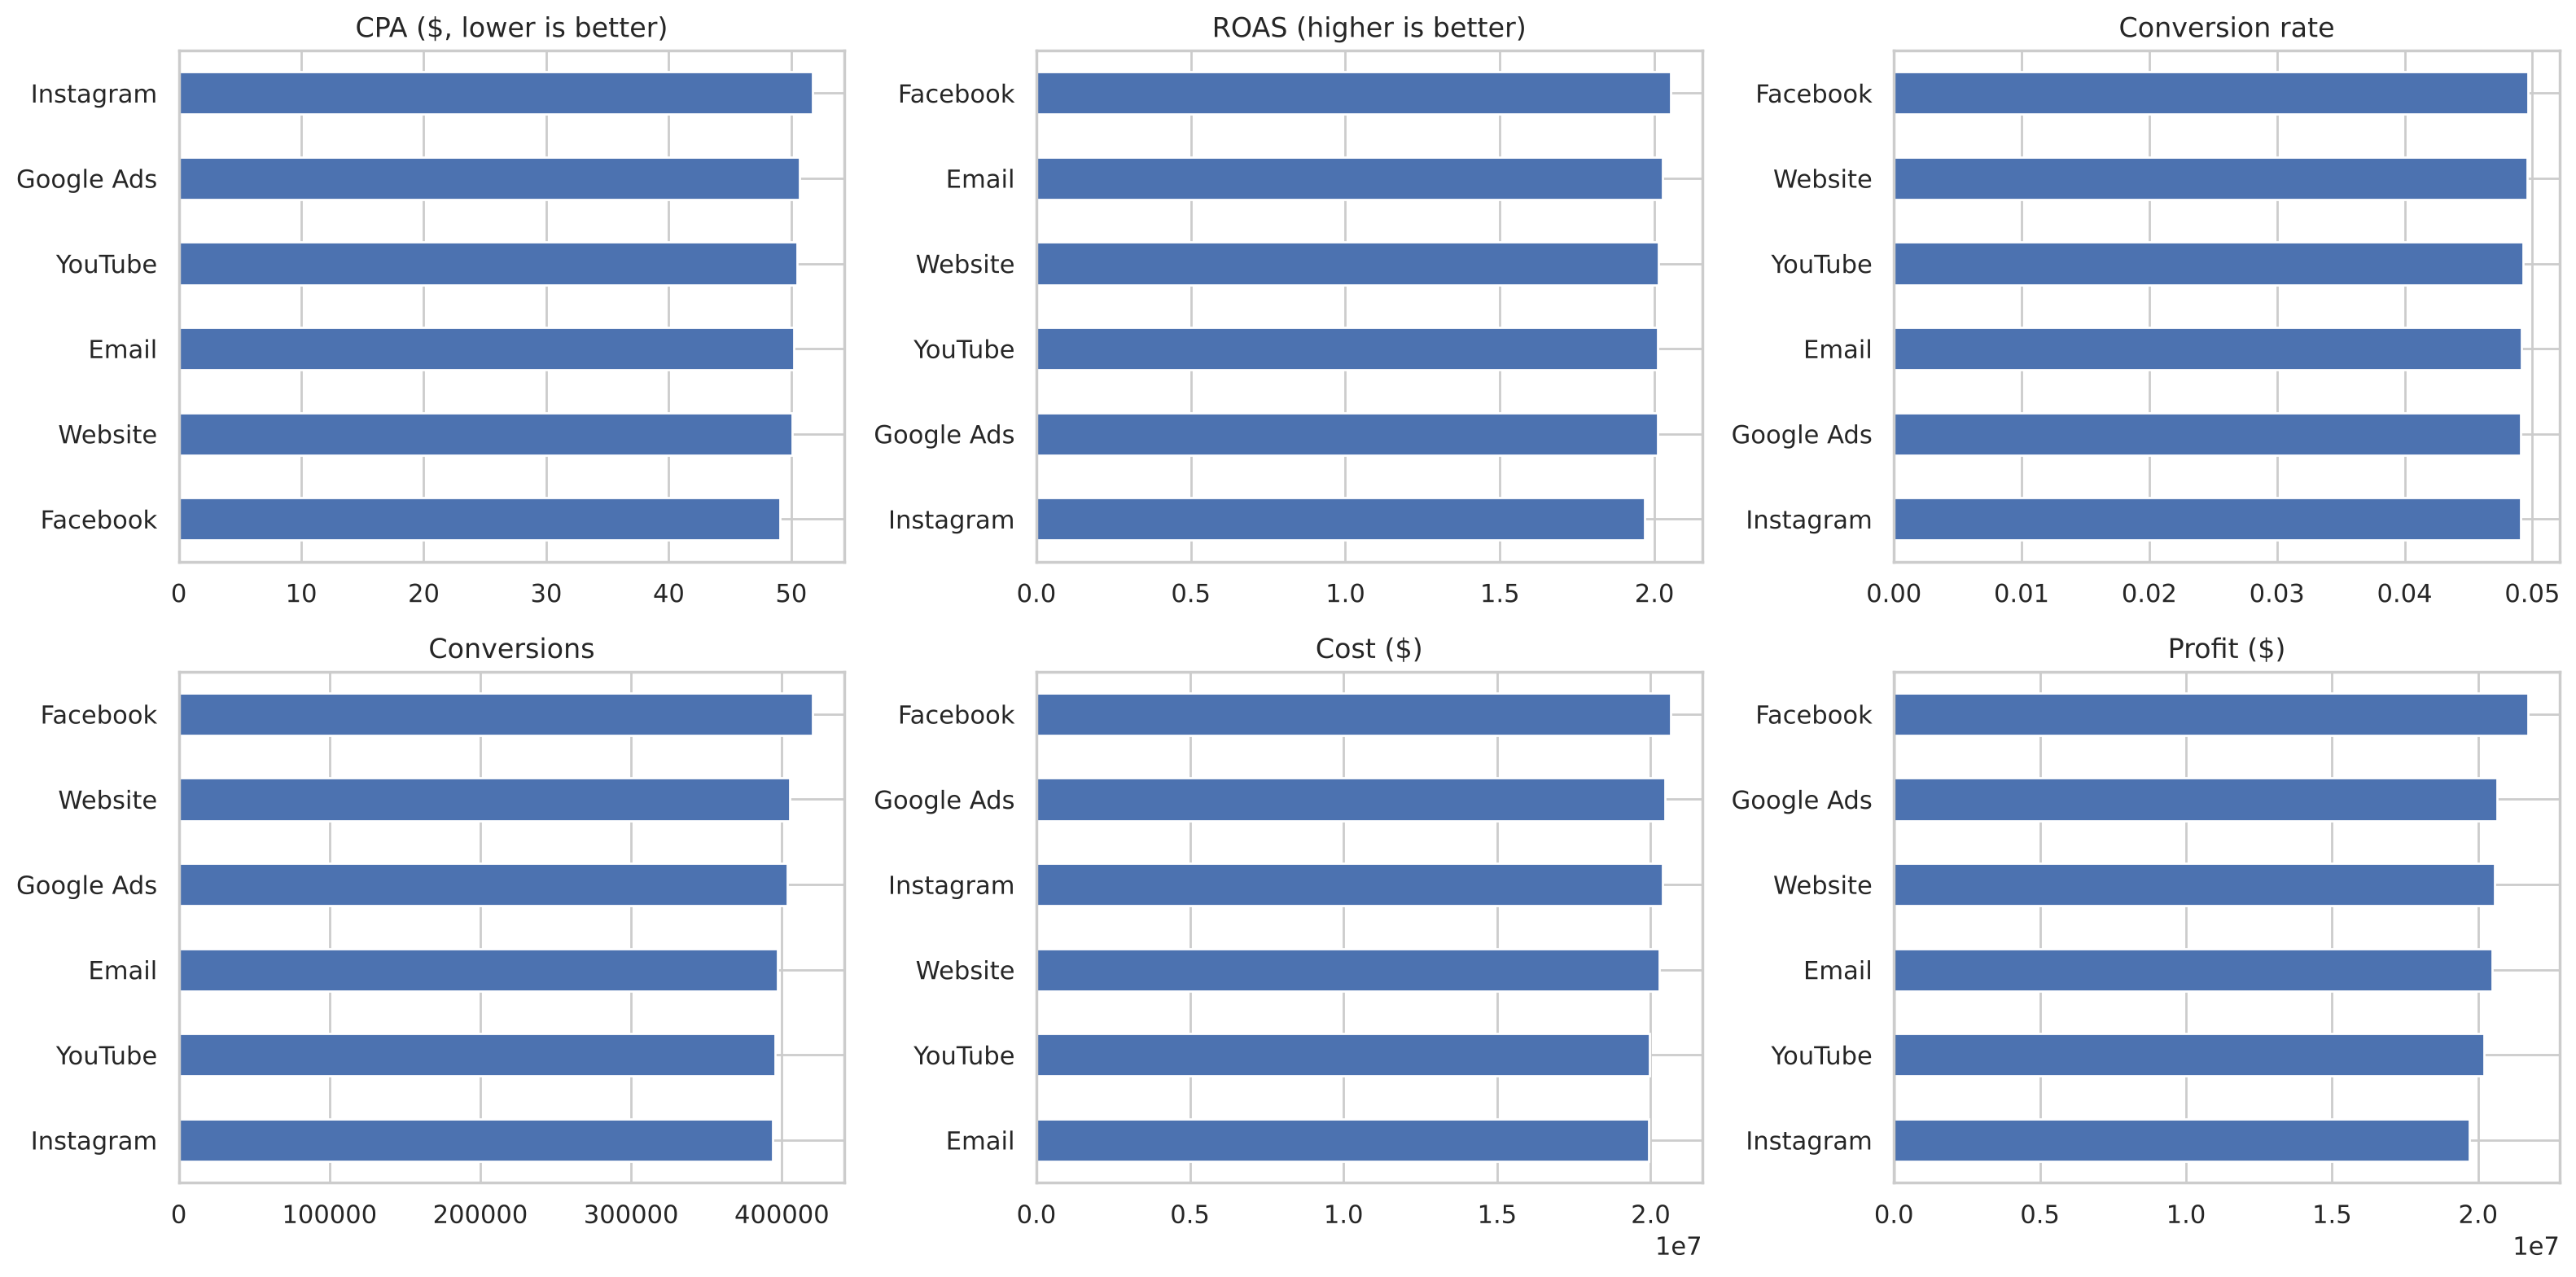

In [5]:
# 2x3 grid of horizontal bar charts
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
charts = [
    ("CPA", "CPA ($, lower is better)"),
    ("ROAS", "ROAS (higher is better)"),
    ("conv_rate", "Conversion rate"),
    ("conversions", "Conversions"),
    ("cost", "Cost ($)"),
    ("profit", "Profit ($)"),
]
for ax, (col, title) in zip(axes.flat, charts):
    agg[col].sort_values().plot.barh(ax=ax)
    ax.set_title(title)
    ax.set_ylabel("")

# Profit chart: vertical line at 0
axes.flat[5].axvline(0, color="black")
plt.tight_layout()
plt.savefig(OUT / "group_metrics_overview.png", dpi=120)
plt.show()

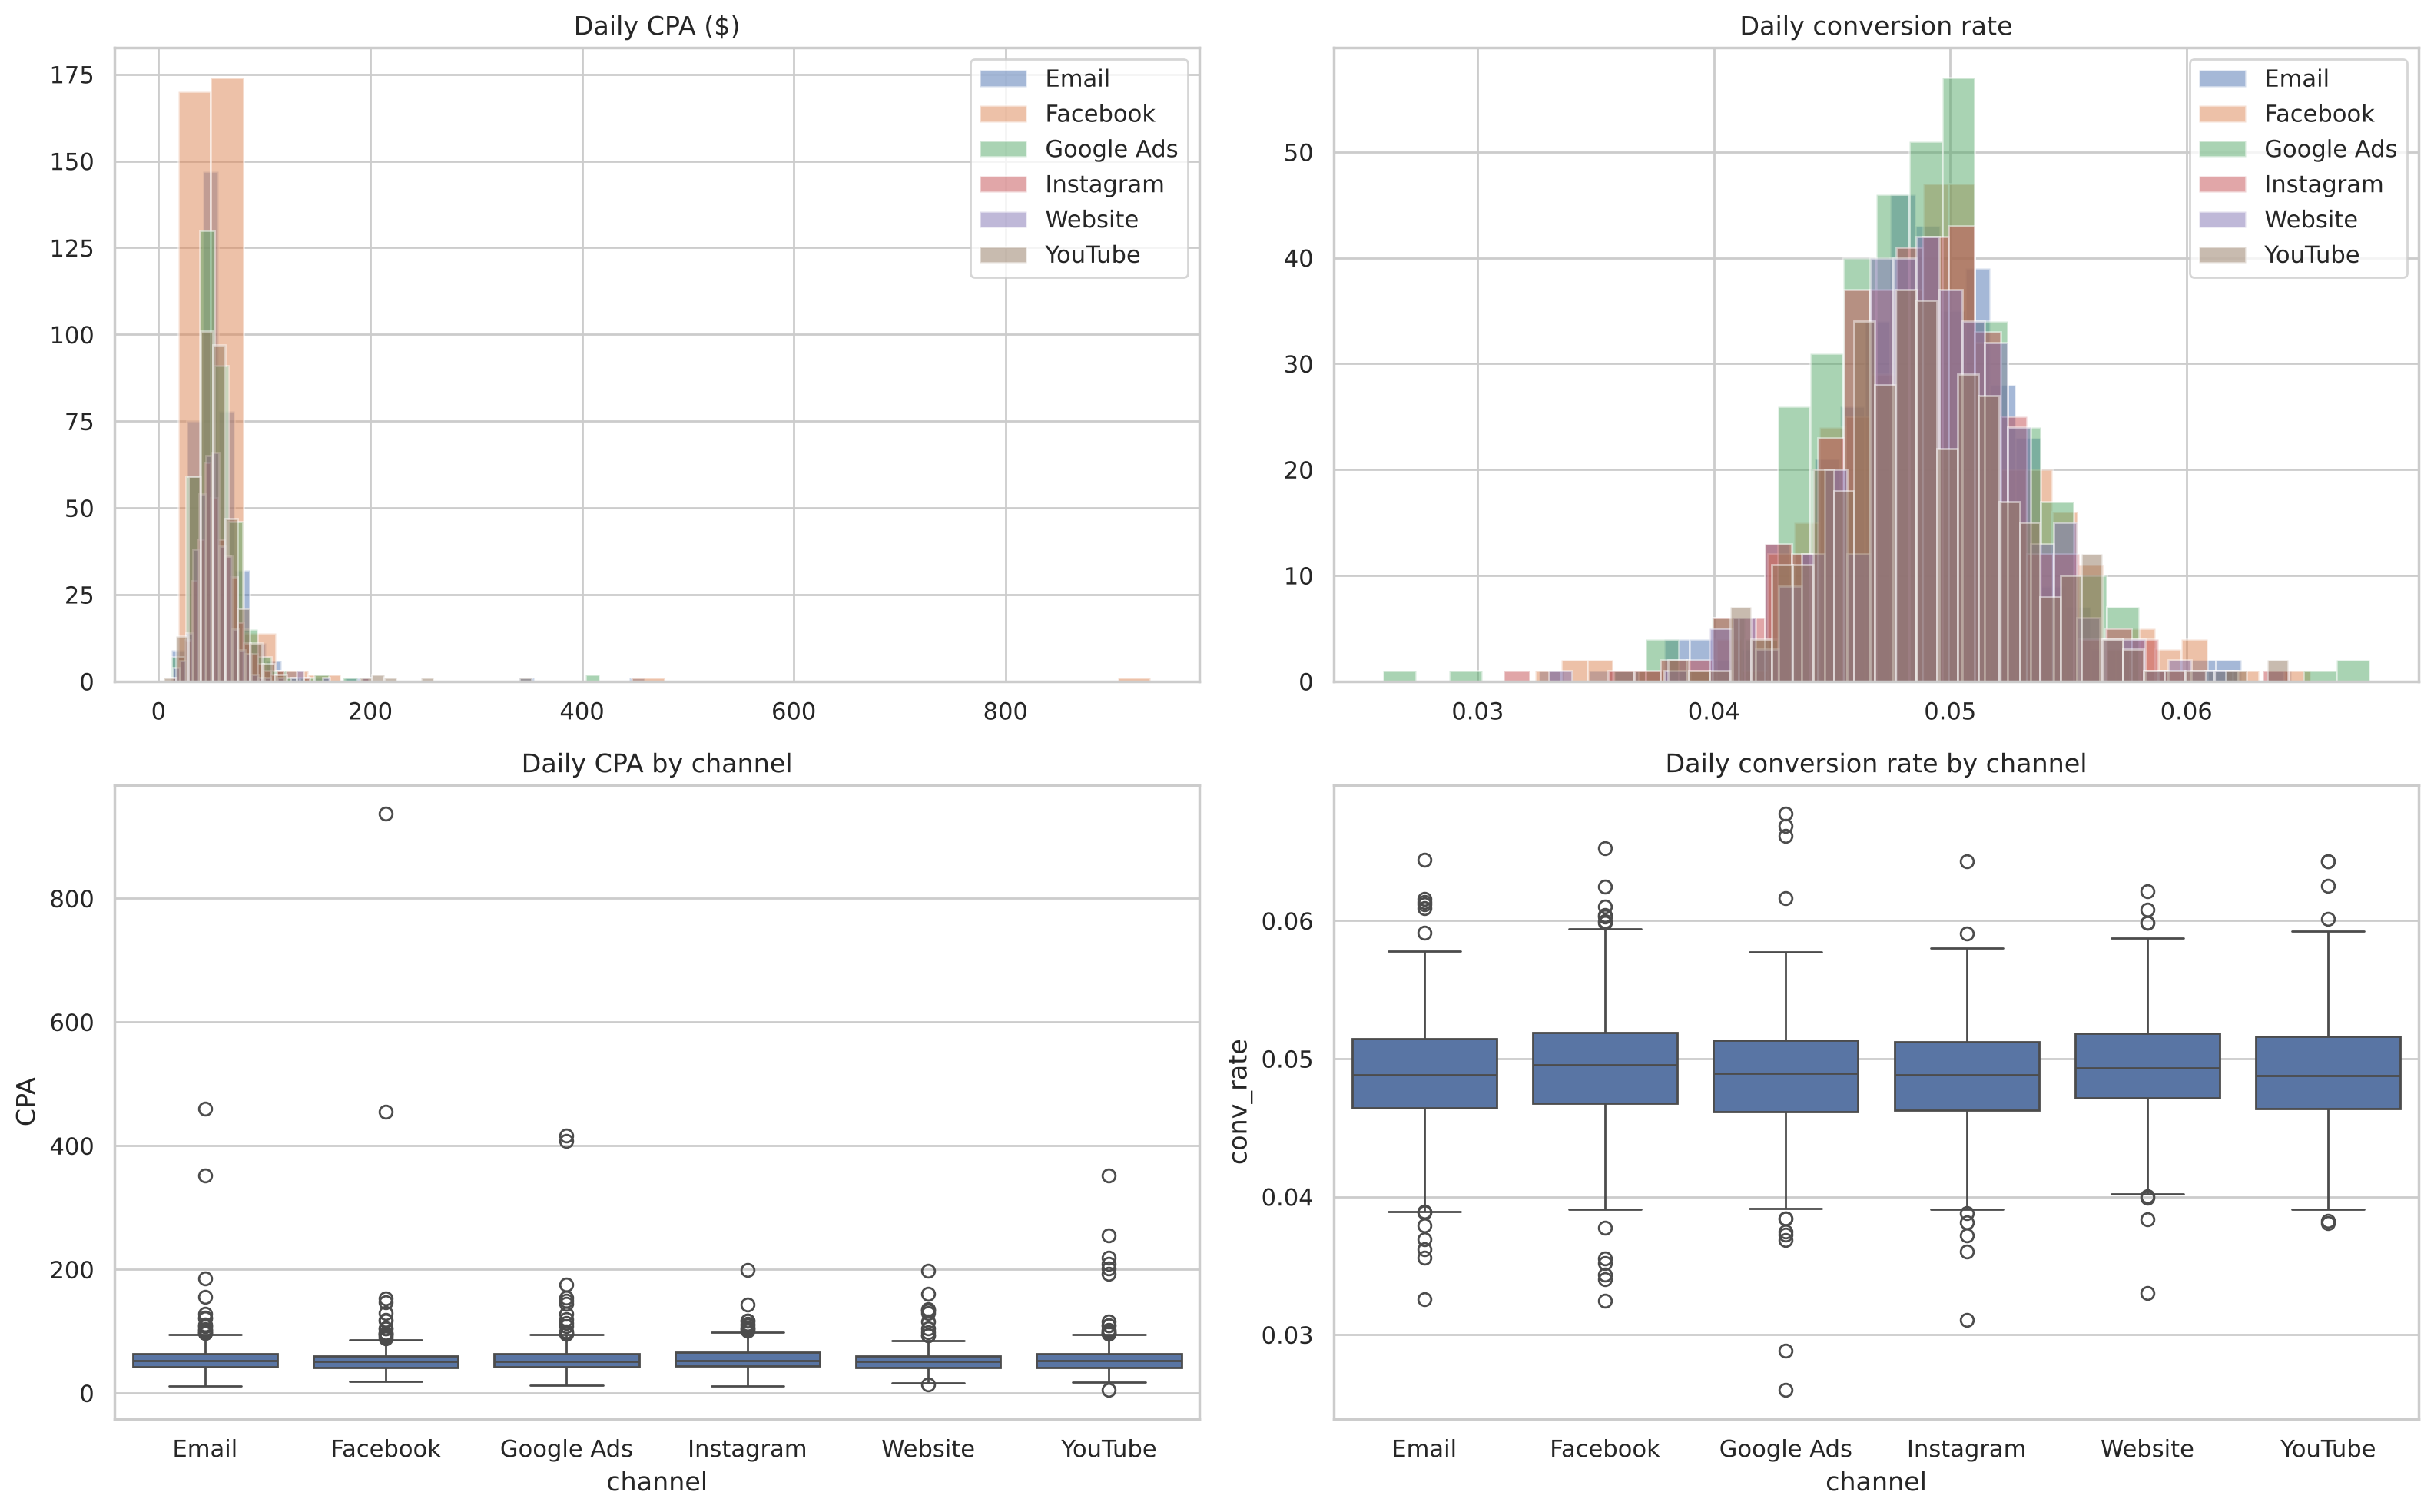

,mean,std,CV
channel,,,
Email,56.536,33.015,0.584
Facebook,55.885,53.635,0.960
Google Ads,56.774,33.177,0.584
Instagram,55.953,19.850,0.355
Website,53.056,19.302,0.364
YouTube,56.294,29.860,0.530


In [6]:
# Per-day metrics -> these give the SPREAD we need for t-tests
df["CPA"] = df["cost"] / df["conversions"]
df["conv_rate"] = df["conversions"] / df["clicks"]
df = df.replace([np.inf, -np.inf], np.nan)
paid = df[df.cost > 0]

# Histograms (overlaid) and box plots of daily CPA and conversion rate
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ch in sorted(paid["channel"].unique()):
    axes[0, 0].hist(paid[paid["channel"] == ch]["CPA"], bins=30, alpha=0.5, label=ch)
    axes[0, 1].hist(df[df["channel"] == ch]["conv_rate"], bins=30, alpha=0.5, label=ch)
axes[0, 0].set_title("Daily CPA ($)")
axes[0, 1].set_title("Daily conversion rate")
axes[0, 0].legend()
axes[0, 1].legend()
sns.boxplot(data=paid, x="channel", y="CPA", ax=axes[1, 0])
sns.boxplot(data=df, x="channel", y="conv_rate", ax=axes[1, 1])
axes[1, 0].set_title("Daily CPA by channel")
axes[1, 1].set_title("Daily conversion rate by channel")
plt.tight_layout()
plt.savefig(OUT / "group_distributions.png", dpi=120)
plt.show()

# Spread per channel: mean, std and CV of daily CPA
variability = paid.groupby("channel")["CPA"].agg(["mean", "std"])
variability["CV"] = variability["std"] / variability["mean"]
variability.round(3)

**✍️ Key insights:**
- **Best channel on each metric:** Facebook is best on CPA ($49.08), ROAS (2.05), conversion rate (4.97%), conversions and profit. Instagram is the weakest on CPA ($51.76) and ROAS (1.97).
- **But the channels are very close:** CPA ranges only from $49.08 to $51.76 (about 5%), ROAS from 1.97 to 2.05, and CTR is 4.4% on every channel. Spend is also almost equal (~$20M per channel).
- **Most variable channel:** Facebook (daily CPA CV = 0.96), because of a few extreme days (one day has CPA = $937). Website and Instagram are the most stable (CV ≈ 0.35–0.36).
- **Outliers:** every channel has some very high daily CPA values (days with few conversions), visible in the box plots. They pull the **mean daily CPA (~$53–57)** above the **total CPA (~$49–52)**.
- **Which channels look close?** Basically all of them. Website looks slightly cheaper on daily CPA; the others overlap almost completely.

💡 **Remember (§1–2 of the statistics notebook):** each channel's CPA is an **estimate** from a sample of days, not a fact.

## Part 2 — Pairwise comparisons (60–75 min)
### Step 4: t-tests + Cohen's d

For every **pair** of channels: is the gap in average daily CPA bigger than the day-to-day luck?

💡 **Hints:**
- `from itertools import combinations`: `combinations(groups, 2)` gives every pair once.
- Use **Welch's t-test**: `stats.ttest_ind(b, a, equal_var=False)`. Why Welch and not the default? Look at the test table in §4b.
- Cohen's d = (mean_b − mean_a) / √((var_a + var_b) / 2). Scale: < 0.2 negligible · < 0.5 small · < 0.8 medium · ≥ 0.8 large.

In [7]:
def cohens_d(a, b):
    pooled_sd = np.sqrt((a.var() + b.var()) / 2)
    return (b.mean() - a.mean()) / pooled_sd

def effect_label(d):
    d = abs(d)
    if d < 0.2:
        return "negligible"
    elif d < 0.5:
        return "small"
    elif d < 0.8:
        return "medium"
    else:
        return "large"

def pairwise_ttests(data, metric):
    clean = data[["channel", metric]].replace([np.inf, -np.inf], np.nan).dropna()
    clean = clean[clean[metric] > 0]
    rows = []
    for a, b in combinations(sorted(clean.channel.unique()), 2):
        xa = clean[clean["channel"] == a][metric]
        xb = clean[clean["channel"] == b][metric]
        t, p = stats.ttest_ind(xb, xa, equal_var=False)
        diff = xb.mean() - xa.mean()
        d = cohens_d(xa, xb)
        rows.append({"group_a": a, "group_b": b, "mean_a": xa.mean(), "mean_b": xb.mean(),
                     "diff": diff, "pct_diff": diff / xa.mean() * 100, "t_stat": t, "p_value": p,
                     "cohens_d": d, "effect": effect_label(d), "significant": p < ALPHA})
    res = pd.DataFrame(rows)
    print(f"{metric}: {len(res)} comparisons, {res.significant.sum()} significant")
    return res

cpa_res = pairwise_ttests(paid, "CPA")
cvr_t_res = pairwise_ttests(df, "conv_rate")
cpa_res.round(4)

CPA: 15 comparisons, 1 significant
conv_rate: 15 comparisons, 5 significant


,group_a,group_b,mean_a,mean_b,diff,pct_diff,t_stat,p_value,cohens_d,effect,significant
0,Email,Facebook,56.5365,55.8853,-0.6512,-1.1518,-0.1975,0.8435,-0.0146,negligible,False
1,Email,Google Ads,56.5365,56.7744,0.2379,0.4208,0.0971,0.9227,0.0072,negligible,False
2,Email,Instagram,56.5365,55.9531,-0.5833,-1.0318,-0.2892,0.7725,-0.0214,negligible,False
3,Email,Website,56.5365,53.0562,-3.4803,-6.1559,-1.7386,0.0826,-0.1287,negligible,False
4,Email,YouTube,56.5365,56.2942,-0.2423,-0.4286,-0.1039,0.9173,-0.0077,negligible,False
5,Facebook,Google Ads,55.8853,56.7744,0.8891,1.5910,0.2693,0.7878,0.0199,negligible,False
6,Facebook,Instagram,55.8853,55.9531,0.0679,0.1214,0.0227,0.9819,0.0017,negligible,False
7,Facebook,Website,55.8853,53.0562,-2.8291,-5.0624,-0.9482,0.3435,-0.0702,negligible,False
8,Facebook,YouTube,55.8853,56.2942,0.4089,0.7316,0.1272,0.8989,0.0094,negligible,False
9,Google Ads,Instagram,56.7744,55.9531,-0.8213,-1.4466,-0.4057,0.6851,-0.0300,negligible,False


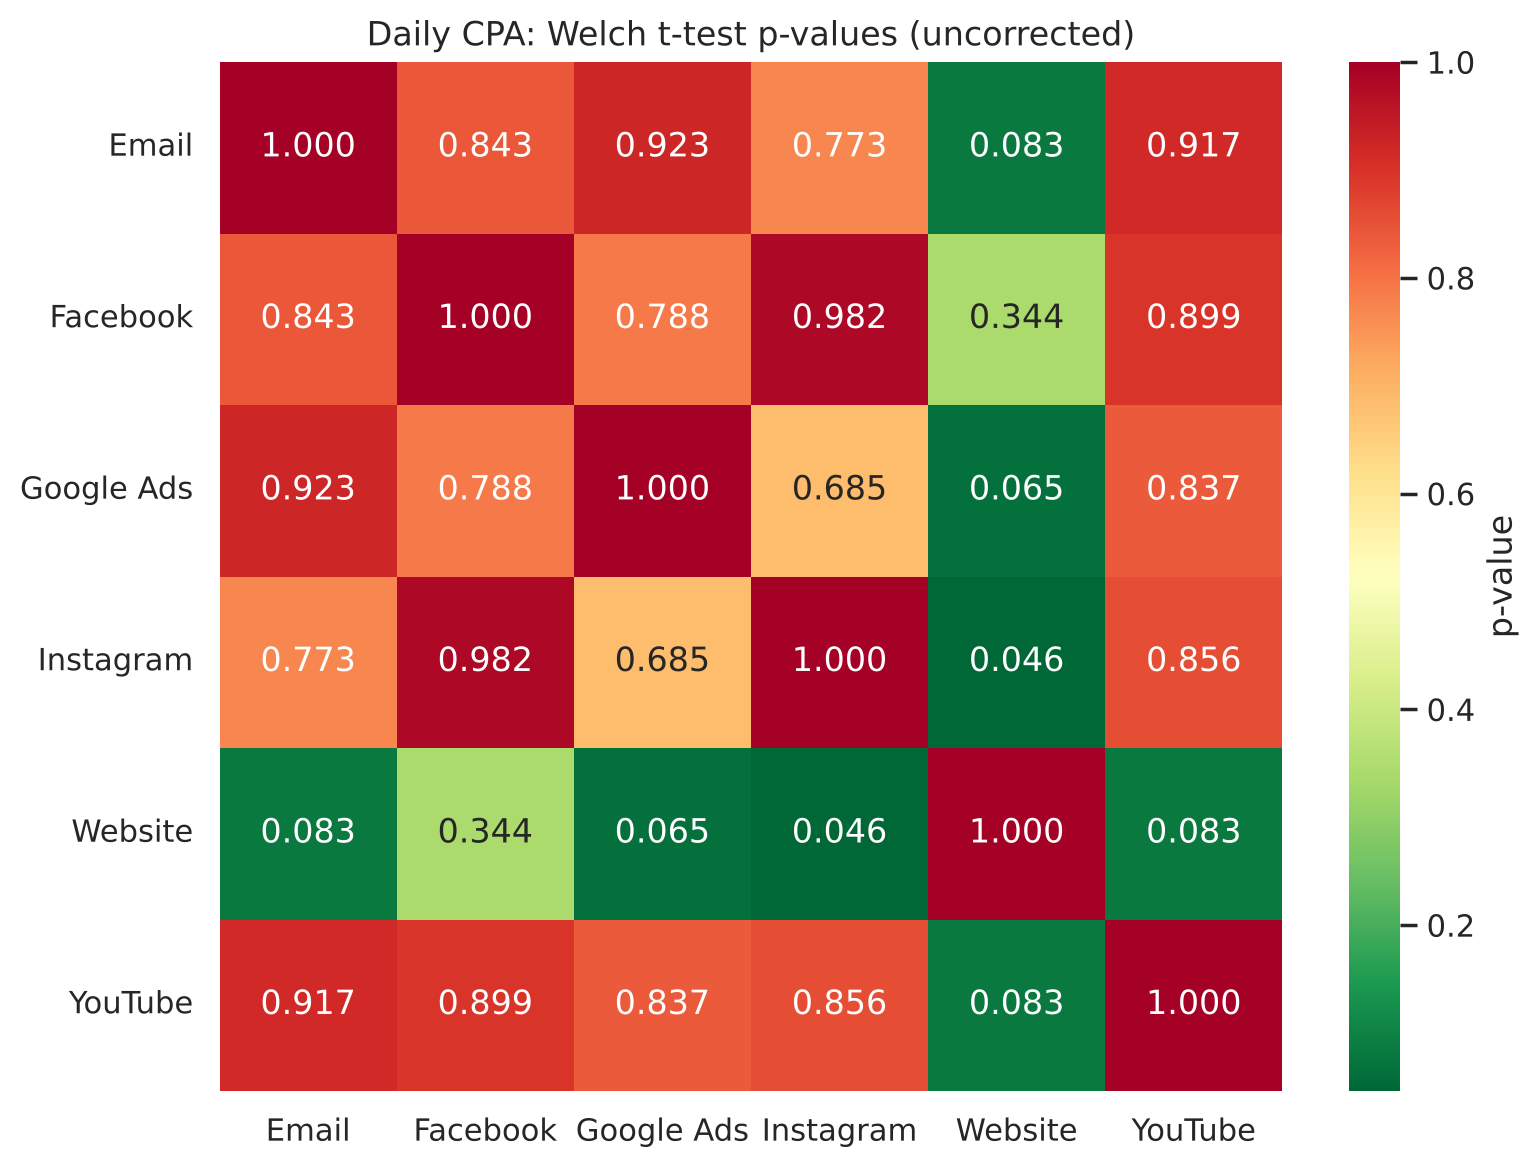

In [8]:
# Heatmap of CPA p-values (channels x channels)
channels = sorted(paid["channel"].unique())
p_matrix = pd.DataFrame(1.0, index=channels, columns=channels)
for _, row in cpa_res.iterrows():
    p_matrix.loc[row["group_a"], row["group_b"]] = row["p_value"]
    p_matrix.loc[row["group_b"], row["group_a"]] = row["p_value"]

plt.figure(figsize=(8, 6))
sns.heatmap(p_matrix, annot=True, fmt=".3f", cmap="RdYlGn_r", cbar_kws={"label": "p-value"})
plt.title("Daily CPA: Welch t-test p-values (uncorrected)")
plt.tight_layout()
plt.savefig(OUT / "metric_comparison_heatmap.png", dpi=120)
plt.show()

**✍️ Which channels differ significantly? Which pairs can't be told apart?**
- Before any correction, only **1 of 15 pairs** is significant on daily CPA: **Instagram vs Website** (p = 0.046, Website's mean daily CPA is $2.90 lower, Cohen's d = −0.15 → negligible).
- Three other pairs involving Website are close (p ≈ 0.06–0.08: Email, Google Ads and YouTube vs Website), but not below 0.05.
- All other pairs **can't be told apart** (p between 0.34 and 0.98, Cohen's d below 0.15 → all "negligible").

💡 **Remember (§3):** a big p-value means **"can't tell"**, not "no difference".

### Step 5: Fisher's exact test on conversions (30–35 min)

Each click either converts or doesn't: **right/wrong data**, so Fisher's exact test (§4b).

```
[[conversions_A, non_conversions_A],
 [conversions_B, non_conversions_B]]
```

In [9]:
# Totals per channel
conv = df.groupby("channel")[["conversions", "clicks"]].sum()
conv["non_conversions"] = conv["clicks"] - conv["conversions"]
conv["conv_rate"] = conv["conversions"] / conv["clicks"]

rows = []
for a, b in combinations(sorted(conv.index), 2):
    table = [[int(conv.loc[a, "conversions"]), int(conv.loc[a, "non_conversions"])],
             [int(conv.loc[b, "conversions"]), int(conv.loc[b, "non_conversions"])]]
    odds_ratio, p = fisher_exact(table, alternative="two-sided")
    rate_a = conv.loc[a, "conv_rate"]
    rate_b = conv.loc[b, "conv_rate"]
    rows.append({"group_a": a, "group_b": b, "rate_a": rate_a, "rate_b": rate_b,
                 "diff_pp": (rate_b - rate_a) * 100,
                 "pct_diff": (rate_b - rate_a) / rate_a * 100,
                 "odds_ratio": odds_ratio, "p_value": p, "significant": p < ALPHA})
fisher_res = pd.DataFrame(rows)
print(f"Fisher: {len(fisher_res)} comparisons, {fisher_res.significant.sum()} significant")
fisher_res.round(4)

Fisher: 15 comparisons, 8 significant


,group_a,group_b,rate_a,rate_b,diff_pp,pct_diff,odds_ratio,p_value,significant
0,Email,Facebook,0.0492,0.0497,0.0505,1.0267,0.9893,0.0000,True
1,Email,Google Ads,0.0492,0.0491,-0.0038,-0.0779,1.0008,0.7215,False
2,Email,Instagram,0.0492,0.0491,-0.0047,-0.0966,1.0010,0.6596,False
3,Email,Website,0.0492,0.0496,0.0445,0.9060,0.9906,0.0000,True
4,Email,YouTube,0.0492,0.0492,0.0095,0.1927,0.9980,0.3795,False
5,Facebook,Google Ads,0.0497,0.0491,-0.0543,-1.0934,1.0116,0.0000,True
6,Facebook,Instagram,0.0497,0.0491,-0.0552,-1.1119,1.0118,0.0000,True
7,Facebook,Website,0.0497,0.0496,-0.0059,-0.1195,1.0013,0.5778,False
8,Facebook,YouTube,0.0497,0.0492,-0.0410,-0.8255,1.0088,0.0001,True
9,Google Ads,Instagram,0.0491,0.0491,-0.0009,-0.0187,1.0002,0.9323,False


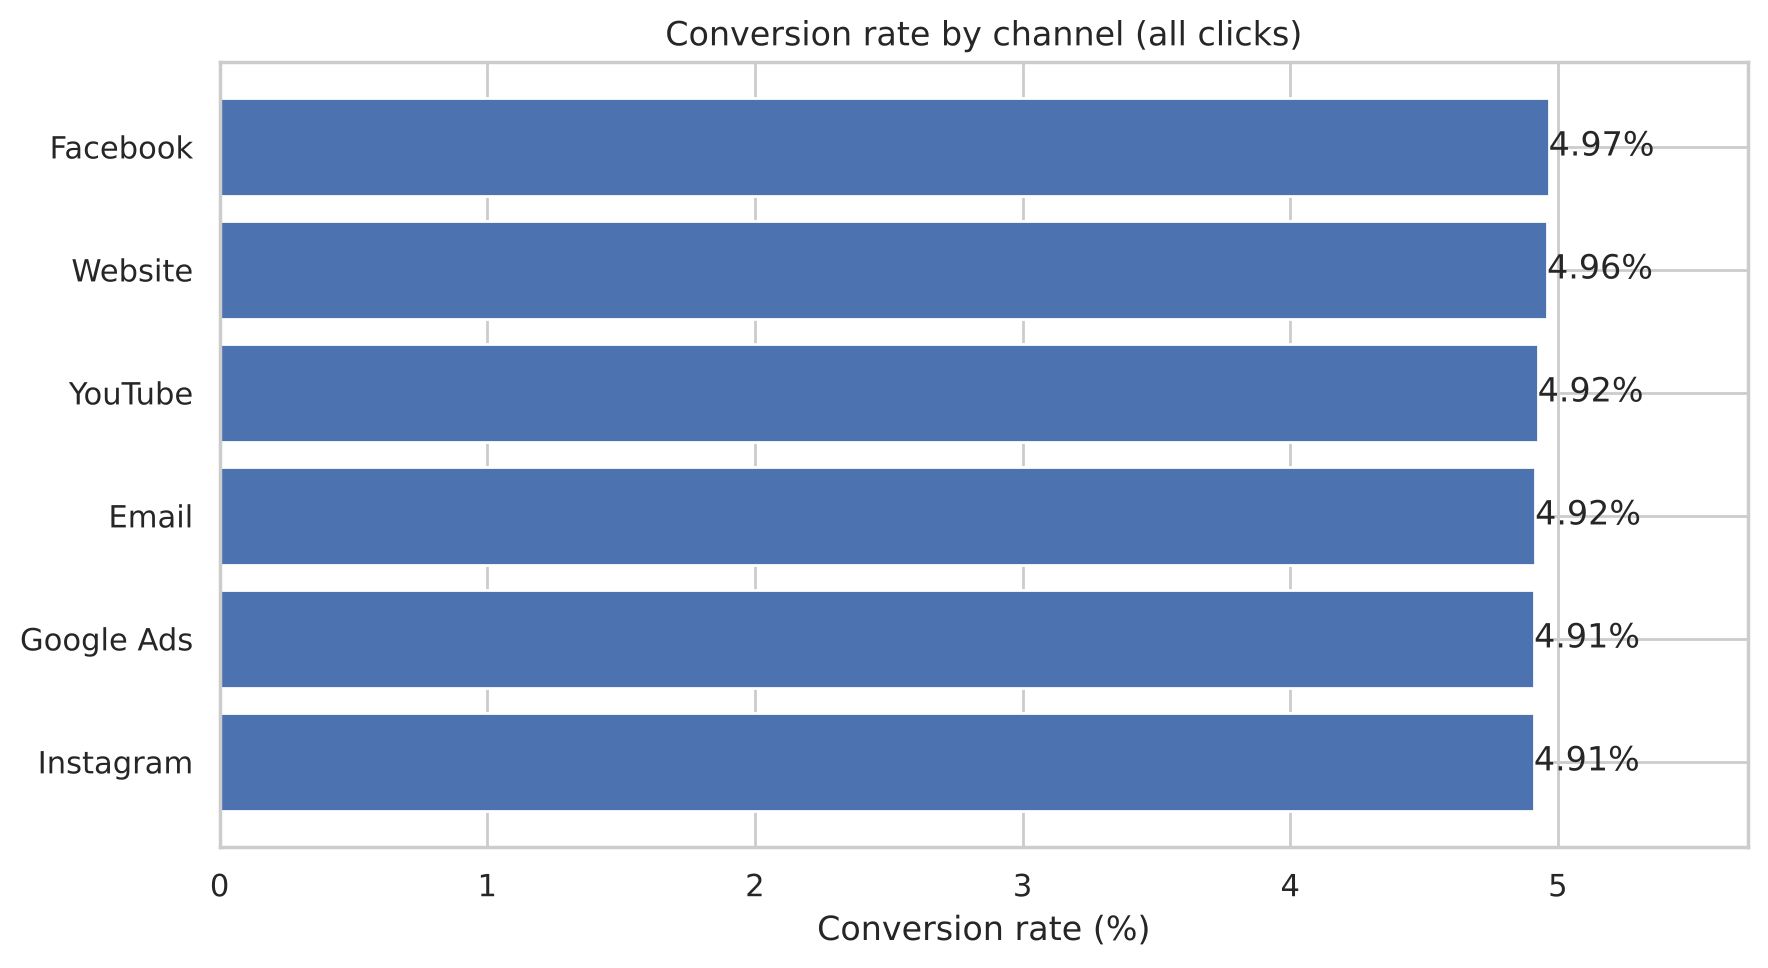

Pairs significant in one test but not the other: 3


,group_a,group_b,diff_pp,p_value_fisher,significant_fisher,p_value_ttest,significant_ttest
0,Email,Facebook,0.0505,0.0000,True,0.0383,True
1,Email,Google Ads,-0.0038,0.7215,False,0.9461,False
2,Email,Instagram,-0.0047,0.6596,False,0.7198,False
3,Email,Website,0.0445,0.0000,True,0.0493,True
4,Email,YouTube,0.0095,0.3795,False,0.4134,False
5,Facebook,Google Ads,-0.0543,0.0000,True,0.0399,True
6,Facebook,Instagram,-0.0552,0.0000,True,0.0149,True
7,Facebook,Website,-0.0059,0.5778,False,0.8106,False
8,Facebook,YouTube,-0.0410,0.0001,True,0.1959,False
9,Google Ads,Instagram,-0.0009,0.9323,False,0.7833,False


In [10]:
# Horizontal bar chart of conversion rates, sorted, with % labels
rates = conv["conv_rate"].sort_values() * 100
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(rates.index, rates.values)
ax.bar_label(bars, fmt="%.2f%%")
ax.set_xlabel("Conversion rate (%)")
ax.set_xlim(0, rates.max() * 1.15)
ax.set_title("Conversion rate by channel (all clicks)")
plt.tight_layout()
plt.savefig(OUT / "rate_comparison.png", dpi=120)
plt.show()

# Compare Fisher with the t-test on daily conversion rates
compare = fisher_res[["group_a", "group_b", "diff_pp", "p_value", "significant"]].merge(
    cvr_t_res[["group_a", "group_b", "p_value", "significant"]],
    on=["group_a", "group_b"], suffixes=("_fisher", "_ttest"))
disagree = compare[compare["significant_fisher"] != compare["significant_ttest"]]
print("Pairs significant in one test but not the other:", len(disagree))
compare.round(4)

**✍️ Answer:**
1. **Which channels have significantly different conversion rates?** With Fisher's test, **8 of 15 pairs** are significant. The pattern is simple: **Facebook (4.97%) and Website (4.96%)** convert better than **Email, Google Ads, Instagram and YouTube (4.91–4.92%)**. Facebook vs Website and the pairs inside the lower group are not significant.
2. **Are the differences large enough to matter?** **No.** The largest gap is **0.055 percentage points** (Facebook 4.97% vs Instagram 4.91%), about 1% relative. On 8 million clicks that is ~4,500 extra conversions per year per channel — real, but tiny compared with the budget question.
3. **Fisher vs t-test: do they agree?** Mostly, but not completely: Fisher finds 8 significant pairs, the daily t-test 5, and **3 pairs are significant only in Fisher** (Facebook vs YouTube, Google Ads vs Website, Website vs YouTube). **Why:** the **N** is very different. Fisher uses every click (N ≈ 8 million per channel), so even a 0.04-point gap becomes "significant". The t-test uses days (N ≈ 365) and the day-to-day noise is much larger than the gap. As §3b showed: with a huge N, almost any tiny difference becomes significant — that's why we must also look at the size of the gap.

## Part 3 — Multiple comparisons correction (45–60 min)
### Step 6: Bonferroni and Benjamini-Hochberg

💡 **Hints (§8 of the statistics notebook):**
- Bonferroni: significant if `p < ALPHA / number_of_tests`
- BH: `false_discovery_control(p_values, method="bh")` returns **adjusted** p-values; significant if adjusted < ALPHA

In [11]:
families = {"CPA (t-test)": cpa_res, "Conv. rate (t-test)": cvr_t_res, "Conv. rate (Fisher)": fisher_res}

# Total number of tests and expected false positives
total_tests = sum(len(res) for res in families.values())
print("Total tests:", total_tests)
print("Expected false positives if nothing is real:", total_tests * ALPHA)

rows = []
for name, res in families.items():
    m = len(res)
    res["significant_bonferroni"] = res["p_value"] < ALPHA / m
    res["p_value_fdr"] = false_discovery_control(res["p_value"], method="bh")
    res["significant_fdr"] = res["p_value_fdr"] < ALPHA
    rows.append({"family": name, "tests": m, "uncorrected": res["significant"].sum(),
                 "Bonferroni": res["significant_bonferroni"].sum(), "BH-FDR": res["significant_fdr"].sum()})
correction_summary = pd.DataFrame(rows).set_index("family")
correction_summary

Total tests: 45
Expected false positives if nothing is real: 2.25


,tests,uncorrected,Bonferroni,BH-FDR
family,,,,
CPA (t-test),15,1,0,0
Conv. rate (t-test),15,5,0,0
Conv. rate (Fisher),15,8,8,8


--- CPA (t-test) ---
Lost with Bonferroni: ['Instagram vs Website']
Lost with BH-FDR:     ['Instagram vs Website']
--- Conv. rate (t-test) ---
Lost with Bonferroni: ['Email vs Facebook', 'Email vs Website', 'Facebook vs Google Ads', 'Facebook vs Instagram', 'Instagram vs Website']
Lost with BH-FDR:     ['Email vs Facebook', 'Email vs Website', 'Facebook vs Google Ads', 'Facebook vs Instagram', 'Instagram vs Website']
--- Conv. rate (Fisher) ---
Lost with Bonferroni: []
Lost with BH-FDR:     []


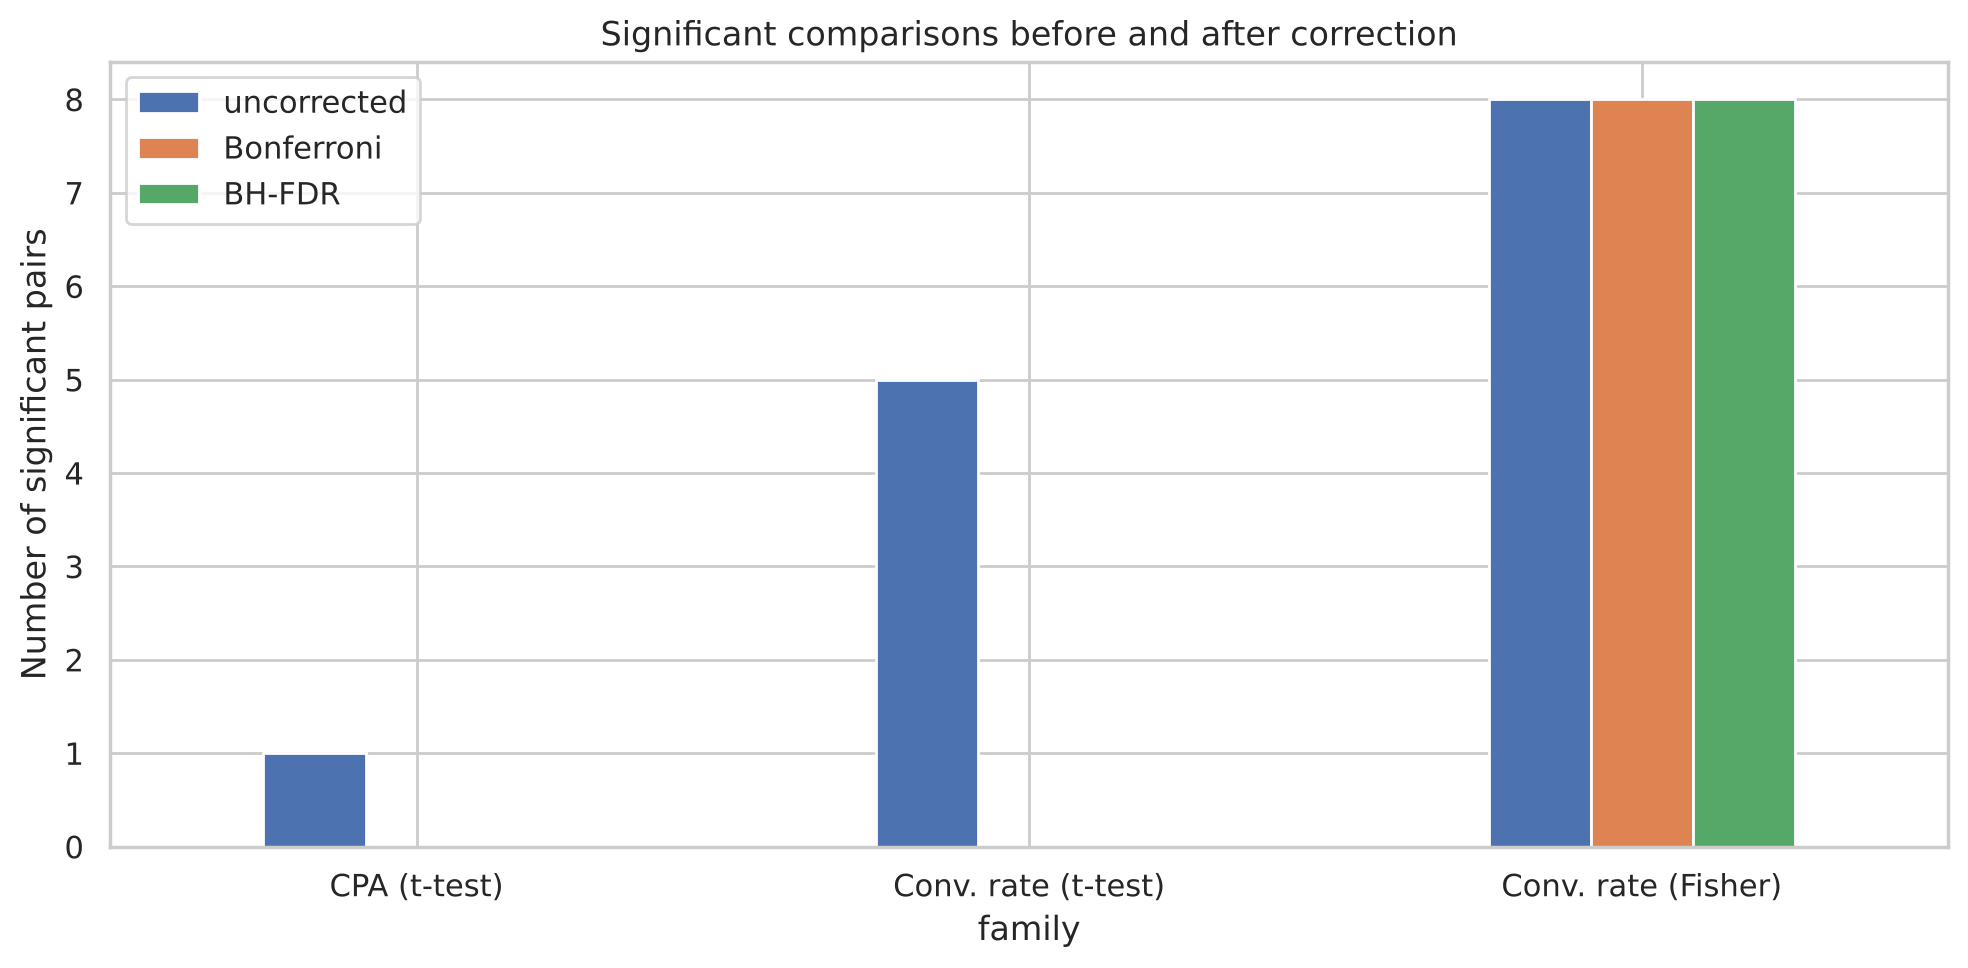

In [12]:
# Which comparisons lose significance after each correction?
for name, res in families.items():
    lost_bonf = res[res["significant"] & ~res["significant_bonferroni"]]
    lost_fdr = res[res["significant"] & ~res["significant_fdr"]]
    print(f"--- {name} ---")
    print("Lost with Bonferroni:", [f"{a} vs {b}" for a, b in zip(lost_bonf.group_a, lost_bonf.group_b)])
    print("Lost with BH-FDR:    ", [f"{a} vs {b}" for a, b in zip(lost_fdr.group_a, lost_fdr.group_b)])

# Grouped bar chart: uncorrected vs Bonferroni vs BH per family
ax = correction_summary[["uncorrected", "Bonferroni", "BH-FDR"]].plot.bar(figsize=(10, 5), rot=0)
ax.set_ylabel("Number of significant pairs")
ax.set_title("Significant comparisons before and after correction")
plt.tight_layout()
plt.savefig(OUT / "correction_comparison.png", dpi=120)
plt.show()

**✍️ Answer:**
1. **How many "significant" results disappeared after correction?** We ran 45 tests, so ~2.25 false positives are expected by chance alone. **6 of 14 significant results disappeared** with both Bonferroni and BH: the only CPA result (Instagram vs Website) and all 5 daily conversion-rate results. The 8 Fisher results survive both corrections (their p-values are tiny because of the huge N).
2. **Which correction fits a budget decision, and why?** Here both corrections give the same answer. In general: a false winner means moving real money to a channel that isn't better, so the cost of a false positive is high. **Bonferroni** (strict, controls the chance of even one false winner) fits a final, hard-to-reverse budget move. **BH** (controls the share of false winners) is better for screening which channels to test next. I use **BH** for the analysis, and would ask for Bonferroni-level evidence before moving a large share of the budget.
3. **What does this mean for moving budget?** There is **no corrected evidence that any channel has a lower CPA**. The only corrected "wins" are conversion-rate gaps of 0.04–0.06 points, which are too small to matter. So the data **does not justify moving budget** between channels.

## Part 4 — Power analysis (30–45 min)
### Step 7: Do we have enough data?

**Power** = the chance of catching a difference that is **really** there (§5). Simulate many experiments where you **know** the truth:
- channel A: daily CPA ~ normal(mean = `base_cpa`, std = 15% of `base_cpa`)
- channel B: the same, but mean = `base_cpa × (1 + true_diff_pct)`
- cap low values at 50% of `base_cpa` (`np.maximum(x, 0.5 * base_cpa)`)
- t-test → count how often p < 0.05

💡 **Speed hint:** draw all simulations at once with shape `(n_sim, n_days)` and use `stats.ttest_ind(a, b, axis=1)`. A plain loop also works, but use `n_sim=300` then.

Base CPA: $50.33


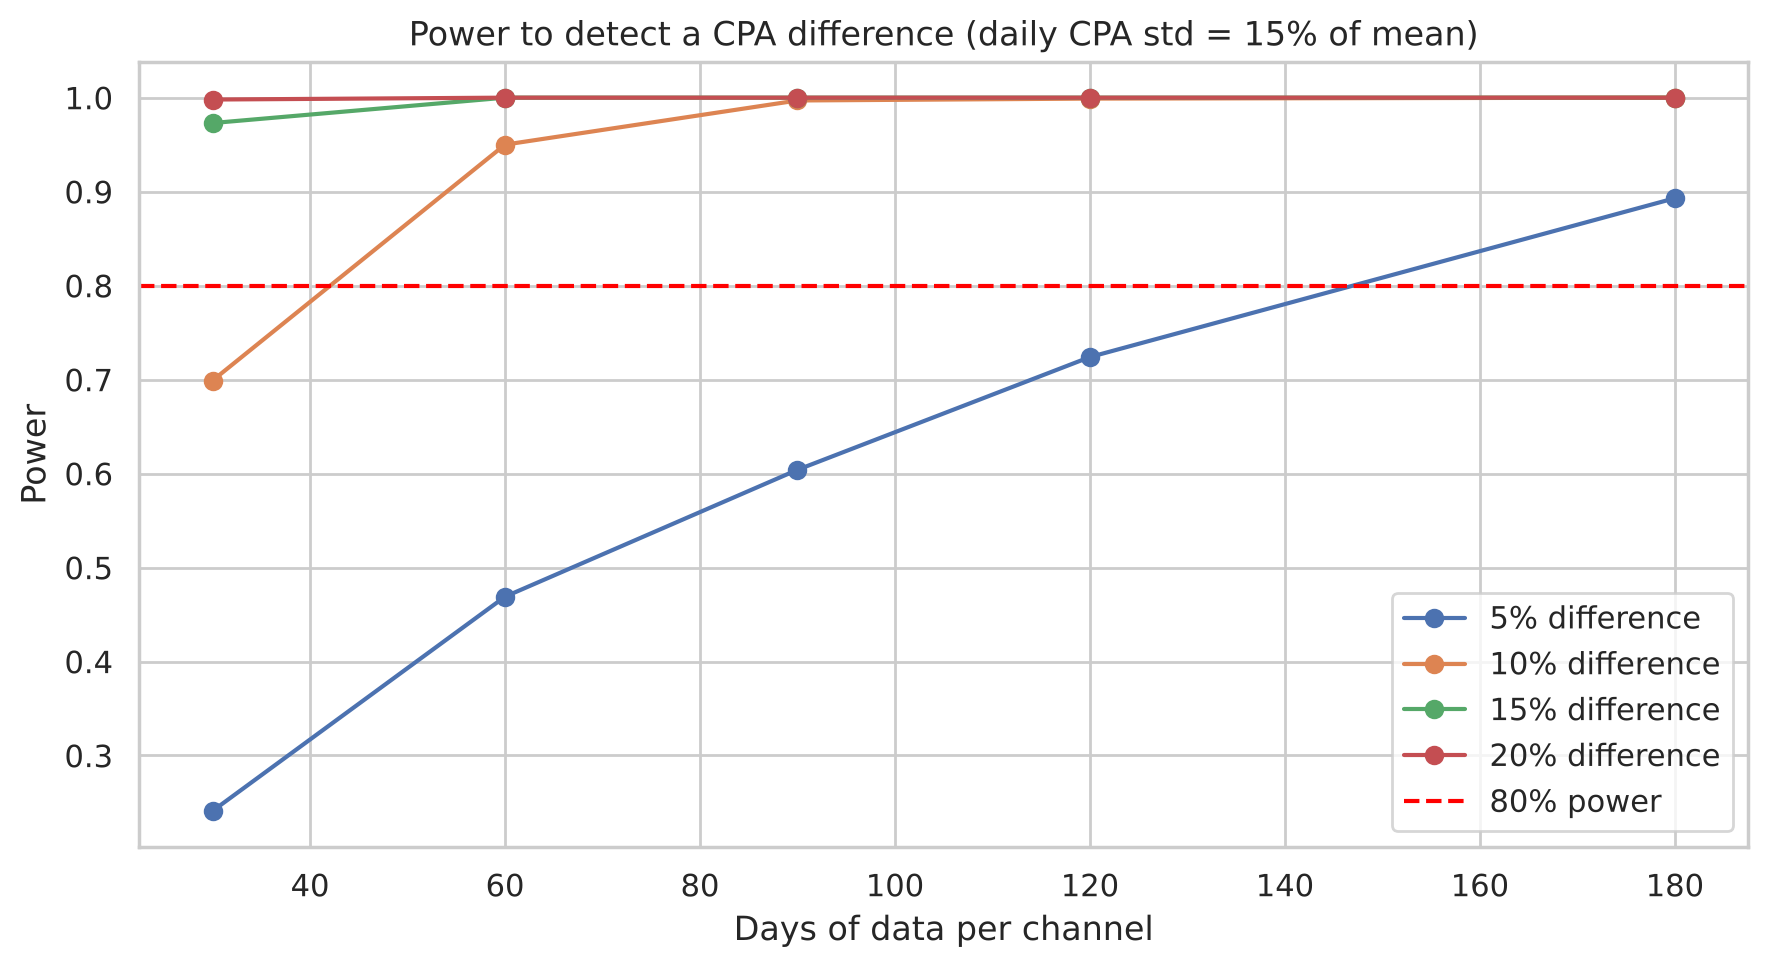

effect_size_pct,0.05,0.10,0.15,0.20
n_days,,,,
30,0.241,0.699,0.973,0.998
60,0.469,0.950,1.000,1.000
90,0.604,0.997,1.000,1.000
120,0.724,0.999,1.000,1.000
180,0.893,1.000,1.000,1.000


In [13]:
def empirical_power_cpa(true_diff_pct, base_cpa, n_days, n_sim=1000, alpha=0.05):
    sd = 0.15 * base_cpa
    a = rng.normal(base_cpa, sd, size=(n_sim, n_days))
    b = rng.normal(base_cpa * (1 + true_diff_pct), sd, size=(n_sim, n_days))
    a = np.maximum(a, 0.5 * base_cpa)
    b = np.maximum(b, 0.5 * base_cpa)
    t, p = stats.ttest_ind(a, b, axis=1)
    return (p < alpha).mean()

BASE_CPA = agg["CPA"].median()       # median CPA of the paid channels
print(f"Base CPA: ${BASE_CPA:.2f}")
effects = [0.05, 0.10, 0.15, 0.20]
days = [30, 60, 90, 120, 180]

# DataFrame with columns effect_size_pct, n_days, power
rows = []
for eff in effects:
    for n in days:
        rows.append({"effect_size_pct": eff, "n_days": n, "power": empirical_power_cpa(eff, BASE_CPA, n)})
power_df = pd.DataFrame(rows)

# One line per effect size, red dashed line at 0.8
plt.figure(figsize=(9, 5))
for eff in effects:
    sub = power_df[power_df["effect_size_pct"] == eff]
    plt.plot(sub["n_days"], sub["power"], marker="o", label=f"{int(eff * 100)}% difference")
plt.axhline(0.8, color="red", linestyle="--", label="80% power")
plt.xlabel("Days of data per channel")
plt.ylabel("Power")
plt.title("Power to detect a CPA difference (daily CPA std = 15% of mean)")
plt.legend()
plt.tight_layout()
plt.savefig(OUT / "power_analysis_cpa.png", dpi=120)
plt.show()
power_df.pivot(index="n_days", columns="effect_size_pct", values="power")

In [14]:
# Minimum days for 80% power, per effect size. Is our data enough?
N_DAYS = paid.groupby("channel").size().min()
print("Days of data per channel:", N_DAYS)

def days_needed(true_diff_pct, base_cpa):
    # increase the number of days by ~10% each step until power reaches 80%
    n = 10
    while n <= 20000:
        if empirical_power_cpa(true_diff_pct, base_cpa, n, n_sim=300) >= 0.8:
            return n
        n = int(n * 1.1) + 10
    return None   # more than 20,000 days needed

rows = []
for eff in effects:
    power_now = empirical_power_cpa(eff, BASE_CPA, N_DAYS)
    rows.append({"effect_size_pct": eff, "min_days_80pct": days_needed(eff, BASE_CPA),
                 "power_with_our_days": power_now,
                 "status": "sufficient" if power_now >= 0.8 else "insufficient"})
min_days_df = pd.DataFrame(rows)
display(min_days_df)

# For each CPA pair significant after BH: observed % difference (smaller mean = baseline),
# power with our number of days, and days needed for 80% if power < 0.8
def pair_power_table(pairs):
    rows = []
    for _, r in pairs.iterrows():
        base = min(r["mean_a"], r["mean_b"])
        obs_diff = abs(r["mean_a"] - r["mean_b"]) / base
        power_now = empirical_power_cpa(obs_diff, base, N_DAYS)
        rows.append({"pair": f"{r['group_a']} vs {r['group_b']}", "observed_pct_diff": obs_diff * 100,
                     "power_with_our_days": power_now,
                     "days_needed_80pct": days_needed(obs_diff, base) if power_now < 0.8 else N_DAYS})
    return pd.DataFrame(rows)

sig_cpa = cpa_res[cpa_res["significant_fdr"]]
if len(sig_cpa) > 0:
    display(pair_power_table(sig_cpa))
else:
    print("No CPA pair is significant after BH.")
    print("Same calculation for the NON-significant pairs (to answer question 3):")
    nonsig_power = pair_power_table(cpa_res)
    display(nonsig_power.round(3))

Days of data per channel: 363


,effect_size_pct,min_days_80pct,power_with_our_days,status
0,0.05,156,0.993,sufficient
1,0.10,46,1.000,sufficient
2,0.15,21,1.000,sufficient
3,0.20,21,1.000,sufficient


No CPA pair is significant after BH.
Same calculation for the NON-significant pairs (to answer question 3):


,pair,observed_pct_diff,power_with_our_days,days_needed_80pct
0,Email vs Facebook,1.165,0.180,2625.0
1,Email vs Google Ads,0.421,0.058,NaN
2,Email vs Instagram,1.043,0.166,3525.0
3,Email vs Website,6.560,1.000,363.0
4,Email vs YouTube,0.430,0.065,NaN
5,Facebook vs Google Ads,1.591,0.333,1440.0
6,Facebook vs Instagram,0.121,0.045,NaN
7,Facebook vs Website,5.332,0.997,363.0
8,Facebook vs YouTube,0.732,0.098,6318.0
9,Google Ads vs Instagram,1.468,0.260,1763.0


**✍️ Answer:**
1. **What size of CPA difference can your data detect reliably?** Under the lab's assumption (daily CPA std = 15% of the mean), our ~363 days per channel give 99% power for a **5%** difference, so on paper we can detect 5%. **But the real day-to-day spread is much bigger** (CV 0.35–0.96 in the variability table, not 0.15). With the real spread, ~363 days only give 80% power for differences of roughly **10–15%**. That explains why the observed 5–7% gaps (e.g. Email vs Website) are not significant even though the 15% simulation says they "should" be.
2. **How many days would you need to detect a 5% difference?** With the 15% assumption: about **156 days** per channel. With the real spread (CV ≈ 0.35–0.5): roughly **800–1,600 days**, i.e. 2–4 years — not realistic.
3. **Non-significant pairs: "no difference" or "not enough data"?** **Not enough data** for most of them. Most observed CPA gaps are 0.1–1.6%; detecting those would need thousands of days even with the optimistic 15% assumption (e.g. Facebook vs Google Ads: 1.6% gap → ~1,400 days). So we **can't tell** — we can't prove the channels are equal, only that any difference is small.

💡 **Remember:** half the difference → about **4× the data**.

## Part 5 — Business recommendations (30–45 min)
### Step 8: From statistics to a decision

In [15]:
# Summary of significant findings (BH-corrected)
print("CPA (t-test, BH-corrected):")
sig_cpa = cpa_res[cpa_res["significant_fdr"]]
if len(sig_cpa) == 0:
    print("  No significant CPA differences between channels.")
for _, r in sig_cpa.iterrows():
    cheaper = r["group_a"] if r["mean_a"] < r["mean_b"] else r["group_b"]
    print(f"  {r['group_a']} vs {r['group_b']}: {cheaper} is cheaper by ${abs(r['diff']):.2f}, "
          f"adjusted p = {r['p_value_fdr']:.4f}, Cohen's d = {r['cohens_d']:.2f} ({r['effect']})")

print("\nConversion rate (Fisher, BH-corrected):")
sig_cvr = fisher_res[fisher_res["significant_fdr"]]
if len(sig_cvr) == 0:
    print("  No significant conversion-rate differences.")
for _, r in sig_cvr.iterrows():
    higher = r["group_a"] if r["rate_a"] > r["rate_b"] else r["group_b"]
    print(f"  {r['group_a']} vs {r['group_b']}: {higher} is higher by {abs(r['diff_pp']):.2f} points, "
          f"adjusted p = {r['p_value_fdr']:.2e}")

print("\nConversion rate (daily t-test, BH-corrected):")
sig_cvr_t = cvr_t_res[cvr_t_res["significant_fdr"]]
if len(sig_cvr_t) == 0:
    print("  No significant conversion-rate differences.")
for _, r in sig_cvr_t.iterrows():
    print(f"  {r['group_a']} vs {r['group_b']}: adjusted p = {r['p_value_fdr']:.4f}")

CPA (t-test, BH-corrected):
  No significant CPA differences between channels.

Conversion rate (Fisher, BH-corrected):
  Email vs Facebook: Facebook is higher by 0.05 points, adjusted p = 1.10e-05
  Email vs Website: Website is higher by 0.04 points, adjusted p = 8.61e-05
  Facebook vs Google Ads: Facebook is higher by 0.05 points, adjusted p = 2.33e-06
  Facebook vs Instagram: Facebook is higher by 0.06 points, adjusted p = 2.33e-06
  Facebook vs YouTube: Facebook is higher by 0.04 points, adjusted p = 2.65e-04
  Google Ads vs Website: Website is higher by 0.05 points, adjusted p = 1.87e-05
  Instagram vs Website: Website is higher by 0.05 points, adjusted p = 1.78e-05
  Website vs YouTube: Website is higher by 0.04 points, adjusted p = 2.13e-03

Conversion rate (daily t-test, BH-corrected):
  No significant conversion-rate differences.


In [16]:
def bootstrap_ci(data, n_bootstrap=1000, ci_level=0.95):
    data = np.asarray(data)
    means = []
    for _ in range(n_bootstrap):
        sample = rng.choice(data, size=len(data), replace=True)
        means.append(sample.mean())
    low = np.percentile(means, (1 - ci_level) / 2 * 100)
    high = np.percentile(means, (1 + ci_level) / 2 * 100)
    return low, high

# Table: channel, mean daily CPA, 95% CI low, 95% CI high
rows = []
for ch in sorted(paid["channel"].unique()):
    values = paid[paid["channel"] == ch]["CPA"].dropna()
    low, high = bootstrap_ci(values)
    rows.append({"channel": ch, "mean_daily_CPA": values.mean(), "ci_low": low, "ci_high": high})
ci_df = pd.DataFrame(rows).sort_values("mean_daily_CPA")
ci_df.round(2)

,channel,mean_daily_CPA,ci_low,ci_high
4,Website,53.06,51.18,55.16
1,Facebook,55.89,51.62,62.57
3,Instagram,55.95,54.15,58.08
5,YouTube,56.29,53.34,59.61
0,Email,56.54,53.41,59.95
2,Google Ads,56.77,53.73,60.18


In [17]:
# Composite score (paid channels only)
score = agg[agg["cost"] > 0][["CPA", "ROAS"]].copy()
score["CPA_rank"] = score["CPA"].rank(ascending=False)    # lowest CPA -> highest rank
score["ROAS_rank"] = score["ROAS"].rank(ascending=True)   # highest ROAS -> highest rank
score["composite"] = 0.5 * score["CPA_rank"] + 0.5 * score["ROAS_rank"]

# Split $500,000 in proportion to the composite score, min 5% / max 35% per channel
BUDGET = 500_000
share = score["composite"] / score["composite"].sum()
for _ in range(20):                       # clip and re-normalise until stable
    share = share.clip(0.05, 0.35)
    share = share / share.sum()
score["share"] = share
score["budget"] = share * BUDGET
score = score.sort_values("budget", ascending=False)
print("Total allocated:", round(score["budget"].sum()))
score.round(3)

Total allocated: 500000


,CPA,ROAS,CPA_rank,ROAS_rank,composite,share,budget
channel,,,,,,,
Facebook,49.080,2.052,6.0,6.0,6.0,0.285,142500.0
Email,50.178,2.027,4.0,5.0,4.5,0.214,106875.0
Website,50.081,2.013,5.0,4.0,4.5,0.214,106875.0
YouTube,50.485,2.011,3.0,3.0,3.0,0.142,71250.0
Google Ads,50.666,2.009,2.0,2.0,2.0,0.095,47500.0
Instagram,51.762,1.967,1.0,1.0,1.0,0.050,25000.0


💡 **Before you write the memo, think:**
- Two channels whose CPA difference is **not significant** still get different ranks. Is that fair?
- The top channel may be **small**. Can it really absorb a big budget at the same CPA?
- Which "significant" differences are **too small to matter**?

In [18]:
# Numbers used in the memo (all taken from the results above)
period = f"{df['date'].min().date()} to {df['date'].max().date()}"
best_cpa, worst_cpa = agg["CPA"].idxmin(), agg["CPA"].idxmax()
best_roas, worst_roas = agg["ROAS"].idxmax(), agg["ROAS"].idxmin()
n_sig_cpa_raw = int(cpa_res["significant"].sum())
n_sig_cpa = int(cpa_res["significant_fdr"].sum())
n_sig_cvr_t = int(cvr_t_res["significant_fdr"].sum())
n_sig_fisher = int(fisher_res["significant_fdr"].sum())
max_pp_gap = fisher_res.loc[fisher_res["significant_fdr"], "diff_pp"].abs().max()
cv_min, cv_max = variability["CV"].min(), variability["CV"].max()
equal_share = BUDGET / len(score)
top_composite = score.index[0]

# Write the executive memo as Markdown and save it
memo = f"""# Executive memo — Marketing budget allocation

**To:** CMO · **From:** Nicolò · **Date:** 23 November 2026 · **Dataset:** Marketing Campaign Performance (22,029 campaigns, 6 channels) · **Period:** {period}

## Executive summary
The six channels perform almost the same. Cost per acquisition sits between ${agg['CPA'].min():.2f} ({best_cpa}) and ${agg['CPA'].max():.2f} ({worst_cpa}), and ROAS between {agg['ROAS'].min():.2f} and {agg['ROAS'].max():.2f}. After correcting for {total_tests} tests, **no channel has a significantly lower CPA than another**. Two channels (Facebook, Website) convert clicks slightly better, but the gap is at most {max_pp_gap:.2f} percentage points, which is too small to matter. **Recommendation: do not move budget on this evidence. Keep an even split (about ${equal_share:,.0f} per channel) and run a controlled test before reallocating.**

## Key findings
- Top performers: {best_cpa} has the lowest CPA (${agg.loc[best_cpa, 'CPA']:.2f}) and the highest ROAS ({agg.loc[best_roas, 'ROAS']:.2f}); {worst_cpa} is the weakest (CPA ${agg.loc[worst_cpa, 'CPA']:.2f}, ROAS {agg.loc[worst_roas, 'ROAS']:.2f}). The whole spread is about {(agg['CPA'].max() / agg['CPA'].min() - 1) * 100:.0f}%.
- Statistically significant differences (after correction): CPA: {n_sig_cpa} of 15 pairs (only {n_sig_cpa_raw} before correction, Instagram vs Website, and it did not survive). Conversion rate, daily t-test: {n_sig_cvr_t} of 15. Conversion rate, Fisher on all clicks: {n_sig_fisher} of 15 pairs, all with gaps of 0.04–0.06 points (about 1% relative). These are "real but tiny": they are significant only because each channel has about 8 million clicks.
- Data adequacy (power): with 363–365 days per channel and the lab's 15% day-to-day spread, we could detect a 5% CPA gap. But the real daily CPA spread is much larger (CV {cv_min:.2f}–{cv_max:.2f}), so in practice we can only reliably detect gaps of roughly 10–15%. The observed gaps (0.1–7%) are below that, so "not significant" here means "can't tell", not "proven equal".

## Recommendations
1. **Keep the split even for now: about ${equal_share:,.0f} per channel.** The composite-score model would give {top_composite} ${score.loc[top_composite, 'budget']:,.0f} and Instagram $25,000, but those ranks come from differences we cannot tell apart from noise. Moving ~$100K on that basis is exactly the false positive we want to avoid.
2. **If you want a tilt, keep it small and reversible** (e.g. ±10% per channel), and treat it as a test, not a decision.
3. **Set up a proper test**: pick the 2–3 channels where a decision would really change spend, run them with a pre-agreed success metric (CPA or ROAS), and size it for a 10% difference (see Next steps).

## Statistical caveats
- Dataset source and limits: public Kaggle-style dataset (GitHub copy). It has no conversion or revenue columns: conversions were derived as clicks × conversion rate and revenue as cost × (1 + ROI). The data looks simulated (CTR is 4.4% on every channel; costs are spread evenly between $1,000 and $9,999), so channel effects may be near zero by design.
- Multiple comparisons correction: {total_tests} tests at α = 0.05 would give about {total_tests * ALPHA:.2f} false positives by chance alone. Benjamini-Hochberg removed the only CPA "win" and all five daily conversion-rate "wins".
- Confidence intervals: the 95% bootstrap intervals for mean daily CPA overlap for every channel (e.g. Website ${ci_df.iloc[0]['ci_low']:.2f}–${ci_df.iloc[0]['ci_high']:.2f}), so no channel is clearly cheaper.
- External factors: no data on seasonality, creative, audience overlap, attribution model or channel saturation. A small channel may not keep its CPA if its budget grows.
- Statistical vs practical significance: the Fisher results are significant but worth about 0.05 points of conversion rate — far below anything that would change the budget.
- Power limitations: the power simulation assumes 15% daily spread; the real spread is 35–96%, so detectable effects are 2–3× larger than the simulation suggests.

## Next steps
- Clean the outliers (days with very few conversions push daily CPA up to $937) and re-run.
- Get real revenue and conversion counts from the ad platforms instead of derived ones.
- Design a 90-day test on the 2–3 channels that matter most, sized for a 10% CPA difference; review results before the next budget cycle.
"""
(OUT / "executive_memo.md").write_text(memo, encoding="utf-8")
display(Markdown(memo))

# Executive memo — Marketing budget allocation

**To:** CMO · **From:** Nicolò · **Date:** 23 November 2026 · **Dataset:** Marketing Campaign Performance (22,029 campaigns, 6 channels) · **Period:** 2023-01-01 to 2023-12-31

## Executive summary
The six channels perform almost the same. Cost per acquisition sits between $49.08 (Facebook) and $51.76 (Instagram), and ROAS between 1.97 and 2.05. After correcting for 45 tests, **no channel has a significantly lower CPA than another**. Two channels (Facebook, Website) convert clicks slightly better, but the gap is at most 0.06 percentage points, which is too small to matter. **Recommendation: do not move budget on this evidence. Keep an even split (about $83,333 per channel) and run a controlled test before reallocating.**

## Key findings
- Top performers: Facebook has the lowest CPA ($49.08) and the highest ROAS (2.05); Instagram is the weakest (CPA $51.76, ROAS 1.97). The whole spread is about 5%.
- Statistically significant differences (after correction): CPA: 0 of 15 pairs (only 1 before correction, Instagram vs Website, and it did not survive). Conversion rate, daily t-test: 0 of 15. Conversion rate, Fisher on all clicks: 8 of 15 pairs, all with gaps of 0.04–0.06 points (about 1% relative). These are "real but tiny": they are significant only because each channel has about 8 million clicks.
- Data adequacy (power): with 363–365 days per channel and the lab's 15% day-to-day spread, we could detect a 5% CPA gap. But the real daily CPA spread is much larger (CV 0.35–0.96), so in practice we can only reliably detect gaps of roughly 10–15%. The observed gaps (0.1–7%) are below that, so "not significant" here means "can't tell", not "proven equal".

## Recommendations
1. **Keep the split even for now: about $83,333 per channel.** The composite-score model would give Facebook $142,500 and Instagram $25,000, but those ranks come from differences we cannot tell apart from noise. Moving ~$100K on that basis is exactly the false positive we want to avoid.
2. **If you want a tilt, keep it small and reversible** (e.g. ±10% per channel), and treat it as a test, not a decision.
3. **Set up a proper test**: pick the 2–3 channels where a decision would really change spend, run them with a pre-agreed success metric (CPA or ROAS), and size it for a 10% difference (see Next steps).

## Statistical caveats
- Dataset source and limits: public Kaggle-style dataset (GitHub copy). It has no conversion or revenue columns: conversions were derived as clicks × conversion rate and revenue as cost × (1 + ROI). The data looks simulated (CTR is 4.4% on every channel; costs are spread evenly between $1,000 and $9,999), so channel effects may be near zero by design.
- Multiple comparisons correction: 45 tests at α = 0.05 would give about 2.25 false positives by chance alone. Benjamini-Hochberg removed the only CPA "win" and all five daily conversion-rate "wins".
- Confidence intervals: the 95% bootstrap intervals for mean daily CPA overlap for every channel (e.g. Website $51.18–$55.16), so no channel is clearly cheaper.
- External factors: no data on seasonality, creative, audience overlap, attribution model or channel saturation. A small channel may not keep its CPA if its budget grows.
- Statistical vs practical significance: the Fisher results are significant but worth about 0.05 points of conversion rate — far below anything that would change the budget.
- Power limitations: the power simulation assumes 15% daily spread; the real spread is 35–96%, so detectable effects are 2–3× larger than the simulation suggests.

## Next steps
- Clean the outliers (days with very few conversions push daily CPA up to $937) and re-run.
- Get real revenue and conversion counts from the ad platforms instead of derived ones.
- Design a 90-day test on the 2–3 channels that matter most, sized for a 10% CPA difference; review results before the next budget cycle.


## Reflection (optional, recommended): `reflection.md`
1. What surprised you about the results?
2. How did multiple-comparison correction change your conclusions?
3. What are the limits of this analysis?
4. How would you explain the findings to a non-technical CMO in one minute?

## Submission checklist
- [ ] GitHub repo with only this lab, plus a `README.md` (how to run + file map)
- [ ] `lab_proof.md` as the entry point (code/workflow, one run with its input, the evidence, the final output, one failure or limitation you hit)
- [ ] Notebook(s) run top to bottom without errors
- [ ] `outputs/`: `marketing_data.csv`, the 5 charts, `executive_memo.md`